# Introduction to Data Science 2026

# Week 3

## Exercise 1 | Working with geospatial data (GIS)

To get at least a bit familiar with [GIS](https://en.wikipedia.org/wiki/Geographic_information_system) data and the concept of map projections, we’ll do a simple task of plotting two data sets that are given in different coordinate systems.

1. Download the [world_m.zip](https://github.com/HY-TKTL/intro-to-data-science-2017/blob/master/world_m.zip) and [cities.zip](https://github.com/HY-TKTL/intro-to-data-science-2017/blob/master/cities.zip) files that each include a set of GIS files. Most notably, the <span style="font-weight: bold">shp</span> files are [Shapefile-files](https://en.wikipedia.org/wiki/Shapefile) with coordinates (don’t look, it’s binary!). The <span style="font-weight: bold">prj</span> files contain information (in plain text, so okay to look) about the coordinate systems. Open the files using your favorite programming environment and packages.  

    <span style="font-weight: 500"> *Hint: We warmly recommend [Geopandas](http://geopandas.org/) for pythonistas.*</span>

In [12]:
# Use this cell for your code

%matplotlib inline

# Task 1: download, extract and read the GIS data
import os
import zipfile
import urllib.request

import geopandas as gpd
import matplotlib.pyplot as plt

# Creat the data folder if it does exist
os.makedirs("data", exist_ok=True)

# download the two zip files
datasets = [
    ("world_m.zip", "https://raw.githubusercontent.com/HY-TKTL/intro-to-data-science-2017/master/world_m.zip"),
    ("cities.zip", "https://raw.githubusercontent.com/HY-TKTL/intro-to-data-science-2017/master/cities.zip"),
]

for name, url in datasets:
    path = os.path.join("data", name)
    if not os.path.exists(path):
        print(f"Downloding {name} ...")
        urllib.request.urlretrieve(url, path)
    with zipfile.ZipFile(path) as z:
        z.extractall("data")

# Read the two shapefile
world = gpd.read_file("data/world_m.shp")
cities = gpd.read_file("data/cities.shp")

print("world:", world.shape, "| CRS:", world.crs)
print("cities:", cities.shape, "| CRS:", cities.crs)
print("world bounds:", world.total_bounds)
print("cities bounds:", cities.total_bounds)


world: (174, 7) | CRS: EPSG:3395
cities: (202, 2) | CRS: EPSG:4326
world bounds: [-20037508.34278924  -7446237.8002663   20037508.34278926  18397473.67661697]
cities bounds: [-175.22056448  -41.29997394  179.21664709   64.15002362]


2. The <span style="font-weight: bold">world_m</span> file contains borders of almost all countries in the world. Plot the world.

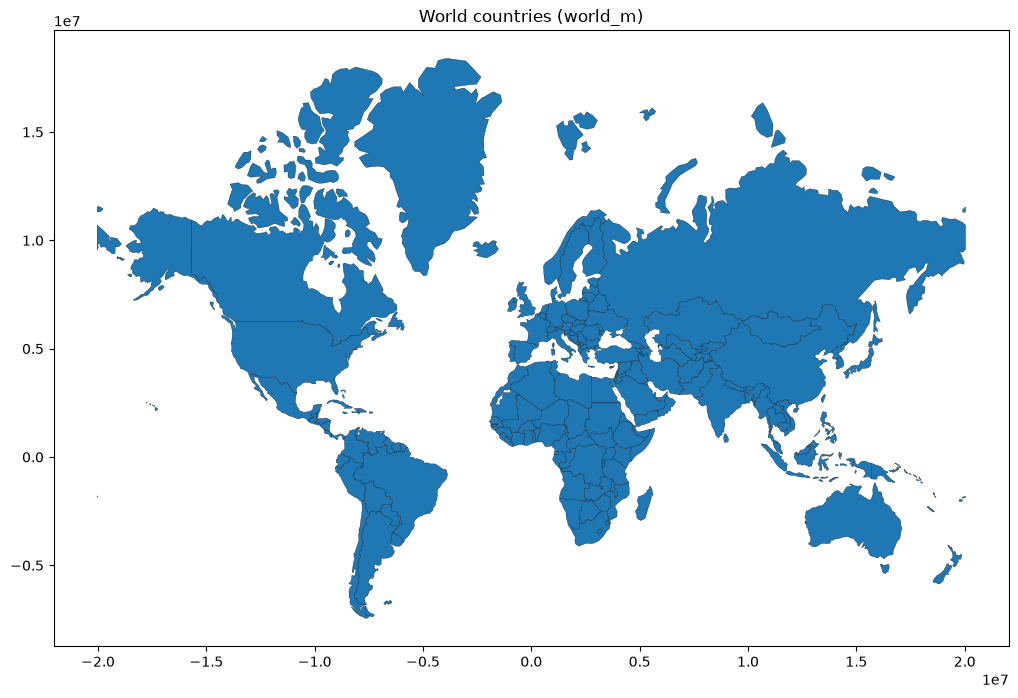

In [13]:
# Use this cell for your code

# Task 2: plot the world
fig, ax = plt.subplots(figsize=(14, 8))
world.plot(ax=ax,edgecolor="black",linewidth=0.2)
ax.set_title("World countries (world_m)")
plt.show()

3. On top of the countries that you just plotted, plot another layer of information, namely the capital cities of each country from the <span style="font-weight: bold">cities</span> dataset. However, depending on how clever your programming environment is, the cities will probably all appear to be in the Gulf of Guinea, near the coordinates (0°, 0°).

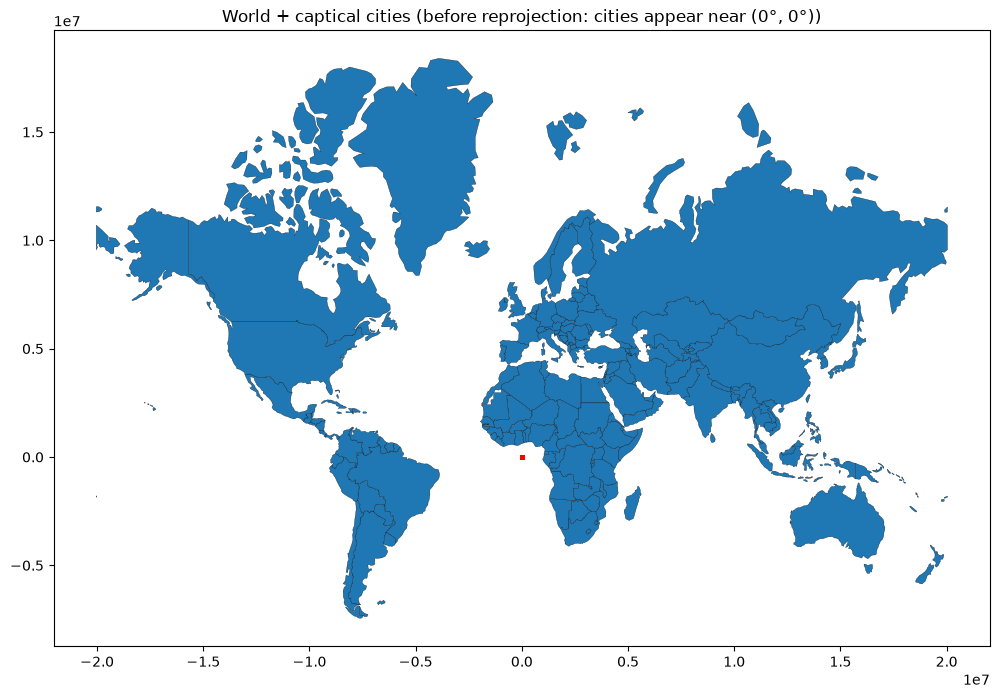

In [14]:
# Use this cell for your code

# Task 3: plot the capital cities on top of the countries
fig, ax = plt.subplots(figsize=(14, 8))
world.plot(ax=ax, edgecolor="black", linewidth=0.2)
cities.plot(ax=ax, color="red", markersize=6)
ax.set_title("World + captical cities (before reprojection: cities appear near (0°, 0°))")
plt.show()

4. Perform a map projection to bring the two data-sets into a shared coordinate system. (You can choose which one.) Now plot the two layers together to make sure the capital cities are where they are supposed to be.

cities projected to: EPSG:3395


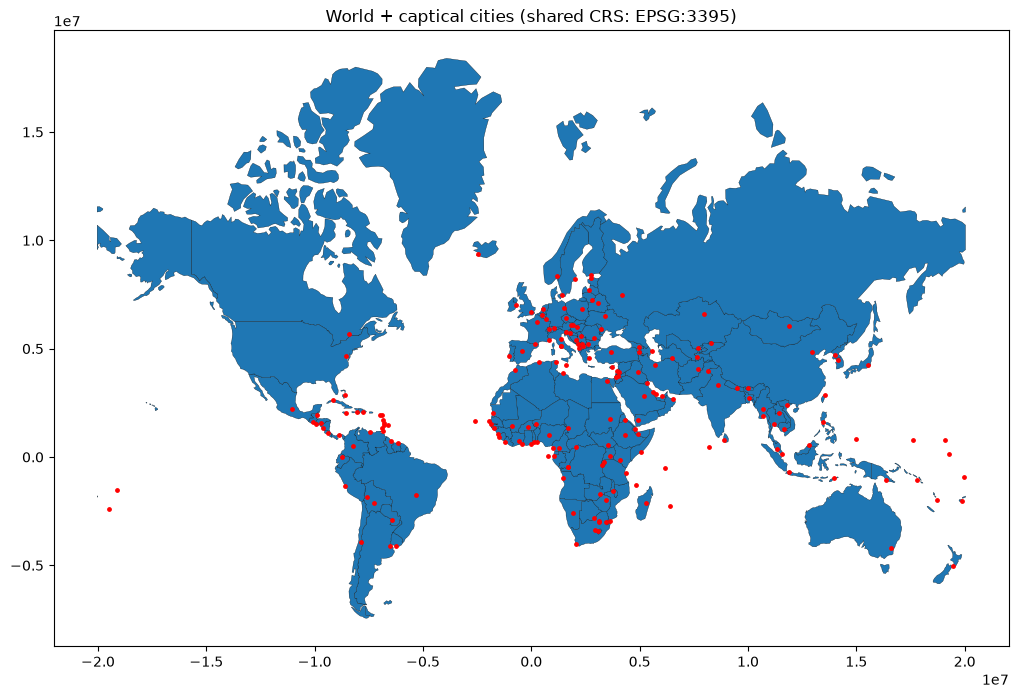

In [15]:
# Use this cell for your code

# Task 4: project both layers to a shard CRS and plot together
cities_proj = cities.to_crs(world.crs)
print("cities projected to:", cities_proj.crs)

fig, ax = plt.subplots(figsize=(14, 8))
world.plot(ax=ax, edgecolor="black", linewidth=0.2)
cities_proj.plot(ax=ax, color="red", markersize=6)
ax.set_title("World + captical cities (shared CRS: EPSG:3395)")
plt.show()

**Remember to submit your code on the MOOC platform. You can return this Jupyter notebook (.ipynb) or .py, .R, etc depending on your programming preferences.**

## Exercise 2 | Symbol classification

We’ll be looking into machine learning by checking out the [HASYv2](https://zenodo.org/record/259444#.Wb7efZ8xDhZ) dataset that contains hand written mathematical symbols as images. The whole dataset is quite big, so we’ll restrict ourselves to doing 10-class classification on some of the symbols. Download the data and complete the following tasks.

1. Extract the data and find inside a file called <span style="font-weight: bold">hasy-data-labels.csv</span>. This file contains the labels for each of the images in the <span style="font-weight: bold">hasy_data</span> folder. Read the labels in and only keep the rows where the <span style="font-weight: bold">symbol_id</span> is within the inclusive range <span style="font-weight: bold">[70, 79]</span>. Read the corresponding images as black-and-white images and flatten them so that each image is a single vector of shape <span style="font-weight: bold">32x32 = 1024</span>. Your dataset should now consist of your input data of shape <span style="font-weight: bold">(1020, 1024)</span> and your labels of shape <span style="font-weight: bold">(1020, )</span>. That is, a matrix of shape <span style="font-weight: bold">1020 x 1024</span> and a vector of size <span style="font-weight: bold">1020</span>.

In [16]:
# Use this cell for your code

# Task 1
import os 
import tarfile
import urllib.request

import numpy as np
import pandas as pd
from PIL import Image

# downlaod and extract HASYv2
os.makedirs("data", exist_ok=True)
archive = os.path.join("data", "HASYv2.tar.bz2")
if not os.path.exists(archive):
    print("Downloading HASYv2 (~47 MB) ...")
    urllib.request.urlretrieve(
        "https://zenodo.org/records/259444/files/HASYv2.tar.bz2?download=1", archive
    )

if not os.path.exists("hasy-data-labels.csv"):
    with tarfile.open(archive) as t:
        t.extractall(".", filter="data")

# read the labels
labels = pd.read_csv("hasy-data-labels.csv")
print("total rows:", len(labels))

# keep only the rows with symbol_id in the inclusive range [70, 79]
labels = labels[(labels["symbol_id"] >= 70) & (labels["symbol_id"] <= 79)]
labels = labels.sort_values("symbol_id").reset_index(drop=True)
print("kept rows:", len(labels))
print("symbols:", sorted(labels["symbol_id"].unique()))

# read the corresponding images as black and white and flatten to 32*32=1024
X = np.zeros((len(labels), 1024))
y = labels["symbol_id"].to_numpy()

for i, path in enumerate(labels["path"]):
    img = Image.open(path).convert("L")
    X[i] = np.asarray(img).reshape(-1)

print("X.shape:", X.shape)
print("y.shape:", y.shape)

total rows: 168233
kept rows: 1020
symbols: [np.int64(70), np.int64(71), np.int64(72), np.int64(73), np.int64(74), np.int64(75), np.int64(76), np.int64(77), np.int64(78), np.int64(79)]
X.shape: (1020, 1024)
y.shape: (1020,)


2. Randomly shuffle the data, and then split it into training and test sets, using the first 80% of the data for training and the rest for evaluation.

In [17]:
# Use this cell for your code

# Task 2:
from sklearn.utils import shuffle
X, y = shuffle(X, y, random_state=42)

n_train = int(0.8 * len(X))
X_train, X_test = X[:n_train], X[n_train:]
y_train, y_test = y[:n_train], y[n_train:]

print("X train:", X_train.shape, ",y train:", y_train.shape)
print("X test:", X_test.shape, ",y test:", y_test.shape)

X train: (816, 1024) ,y train: (816,)
X test: (204, 1024) ,y test: (204,)


3. Fit a logistic regression classifier on the data. Note that we have a multi-class classification problem, but logistic regression is a binary classifier. For this reason, you will find useful <span style="font-weight: bold">[Sklearn's "multi_class" attribute](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)</span>. Use a multinomial loss and the softmax function to predict the probability of each class as the outcome.  The classifier should select the class with the highest probability. Most library implementations will do this for you - feel free to use one.

In [18]:
# Use this cell for your code

# Task 3
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# losgistic regression convergers better on scaled features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# computes a probability for each class and predicts the class with the highest
model = LogisticRegression(solver="lbfgs", max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

print("training accurary:", model.score(X_train_scaled, y_train))
print("test accurary:", model.score(X_test_scaled, y_test))

training accurary: 1.0
test accurary: 0.8823529411764706


4. In order to evaluate the model, let’s create our own dummy classifier that simply guesses the most common class in the training set (looking at the test set here would be cheating!). Then, evaluate your logistic regression model on the test data, and compare it to the majority class classifier. The logistic regression model should have significantly better accuracy as the dummy model is merely making a guess.

    <span style="font-weight: 500"> *Hint: Sklearn's DummyClassifier( ) might save you a bit of time.*</span>

In [19]:
# Use this cell for your code

# Task 4
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# dummy classifier: always guesses the most frequent class of the training set
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

pred = model.predict(X_test_scaled)

print("Logistic regression accuracy:", accuracy_score(y_test, pred))
print("dummy regression accuracy:", accuracy_score(y_test, dummy_pred))

Logistic regression accuracy: 0.8823529411764706
dummy regression accuracy: 0.08823529411764706


5. Plot some of the images that the logistic classifier misclassified. Can you think of an explanation why they were misclassified? Would you have gotten them right?
    
    <span style="font-weight: 500">*Hint: Matplotlib has a [function](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html) that can help you with plotting.*</span>

Here are some examples of the syntax used to fit a logistic regression classifier (using Sklearn or statsmodel with Python, or GLM with R):

In [20]:
#Sklearn (python)

#from sklearn.linear_model import LogisticRegression

#Fit on the training data set, with:
#X : {array-like, sparse matrix}, shape (n_samples, n_features) , n_samples rows x n_features columns
#with attributes that describe each sample.
#y : array-like, shape (n_samples,) , n_samples target values for each sample.

#model = LogisticRegression()
#model.fit(X, y)

In [21]:
#Statsmodels (python)

#import statsmodels.api as sm
#model = sm.Logit(y, X)

In [22]:
#GLM (R)

#model <- glm(y ~.,family=binomial(link='logit'), data=X)

24 / 204 test images were misclassified


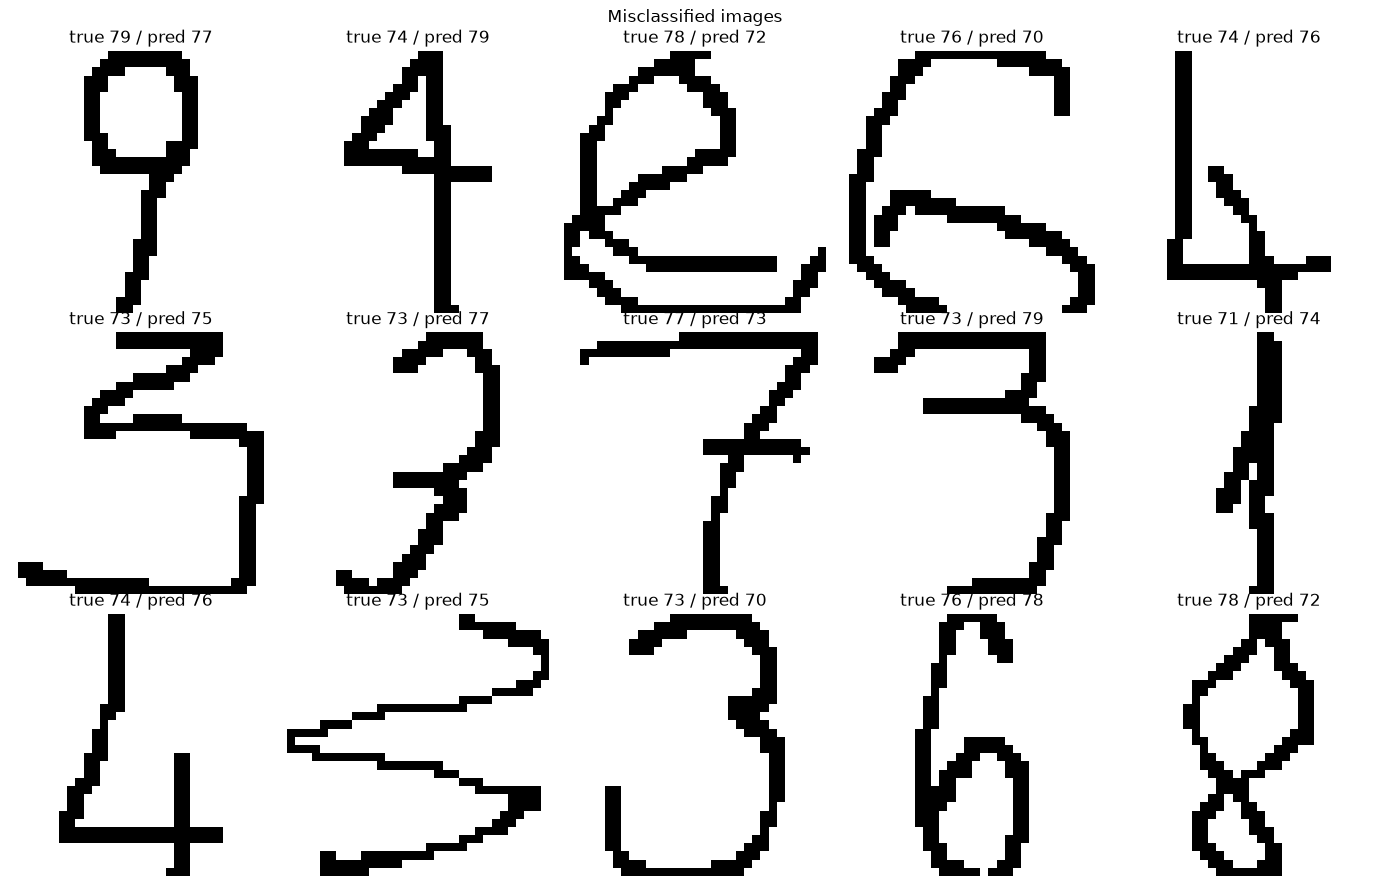

In [23]:
# Use this cell for your code

# Task 5
import matplotlib.pyplot as plt
misclassified = np.where(pred != y_test)[0]
print(f"{len(misclassified)} / {len(y_test)} test images were misclassified")

n = min(15, len(misclassified))
fig, axes = plt.subplots(3, 5, figsize=(14, 9))
for ax, idx in zip(axes.ravel(), misclassified[:n]):
    ax.imshow(X_test[idx].reshape(32, 32), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"true {y_test[idx]} / pred {pred[idx]}")
    ax.axis("off")
plt.suptitle("Misclassified images")
plt.tight_layout()
plt.show()

**Remember to submit your code on the MOOC platform. You can return this Jupyter notebook (.ipynb) or .py, .R, etc depending on your programming preferences.**